# TP 2 — Exercice 2 : Classification d'images avec Fashion-MNIST

In [66]:
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import matplotlib.pyplot as plt
import seaborn as sns

tf.random.set_seed(42)

(x_train,y_train),(x_test,y_test)=fashion_mnist.load_data()

## Étape 1 : Exploration du jeu de données

In [67]:
print(F'dimentions du train set:{x_train.shape}')
print(F'dimentions du test set:{x_test.shape}')

dimentions du train set:(60000, 28, 28)
dimentions du test set:(10000, 28, 28)


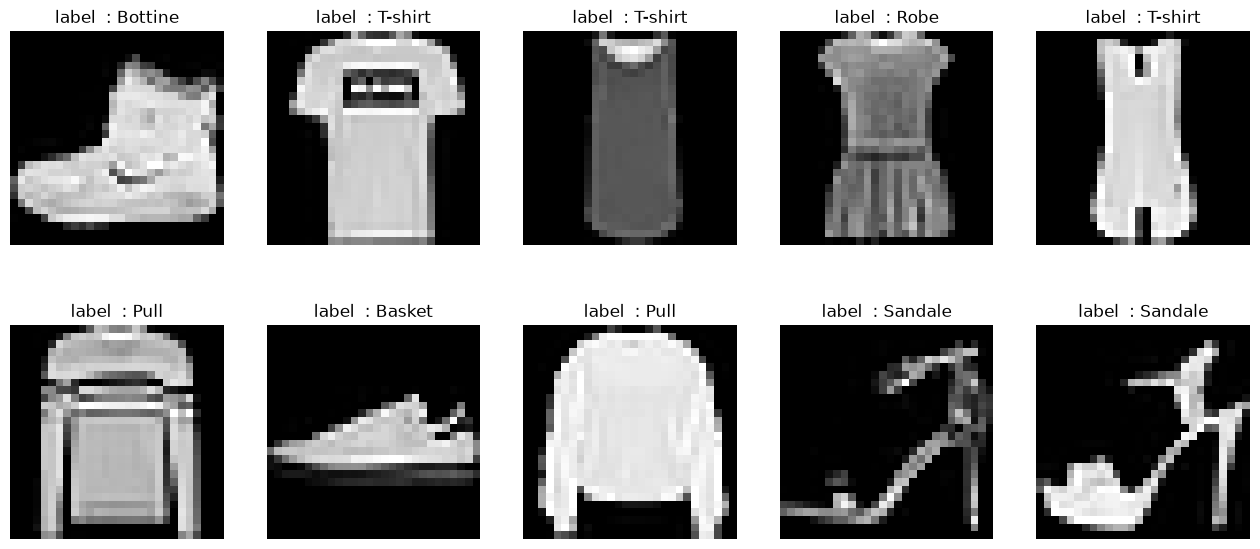

In [68]:
NOMS_CLASSES = ["T-shirt", "Pantalon", "Pull", "Robe", "Manteau",
                "Sandale", "Chemise", "Basket", "Sac", "Bottine"]

plt.figure(figsize=(16,7))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(x_train[i],cmap="gray")
    plt.title(f'label  : {NOMS_CLASSES[y_train[i]]}')
    plt.axis('off')
plt.show()

## Étape 2 : Prétraitement des données

In [69]:
# mis a l'echelle ======================================

x_train=x_train.astype('float32')/255.0
x_test=x_test.astype('float32')/255.0

# Encodage des labels =====================================
y_train_cat=tf.keras.utils.to_categorical(y_train,10)
y_test=tf.keras.utils.to_categorical(y_test,10)

print(y_train_cat[0])

[0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]


### Réponses aux questions — Étape 2

**1. Pourquoi faut-il normaliser les images ?**

Pour ramener tous les pixels dans **[0, 1]** : la descente de gradient converge plus vite et de
façon plus stable quand les entrées sont petites et de même échelle. Sans normalisation,
les gradients seraient instables (grandes valeurs 0–255) et l'entraînement plus lent.

**2. Quelle est l'importance du one-hot encoding dans un problème de classification multiclasse ?**

- Il représente chaque classe par un **vecteur binaire de taille = nombre de classes** :
  aucune **relation d'ordre** artificielle n'est introduite (sinon le modèle pourrait croire
  que « classe 9 > classe 3 », ce qui n'a pas de sens pour des vêtements).
- Il est indispensable avec la perte **`categorical_crossentropy`**, qui compare une
  **distribution prédite** (sortie softmax) à la **distribution cible** one-hot.
- (Alternative : garder des entiers + perte `sparse_categorical_crossentropy`, comme dans l'Exercice 1.)

## Étape 3 : Création d'un modèle dense (ANN)

In [70]:
from tensorflow import keras
from tensorflow.keras import layers

model_ann = keras.Sequential(
    [
        keras.Input(shape=(28, 28)),            # image 28 x 28 en niveaux de gris
        layers.Flatten(),                        # aplatie en vecteur de 784 valeurs
        layers.Dense(128, activation="relu"),    # couche cachée (non-linéarité)
        layers.Dense(10, activation="softmax"),  # 10 classes -> probabilités
    ],
    name="fashion_ann",
)

model_ann.summary()

Model: "fashion_ann"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_32 (Flatten)            │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_86 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_87 (Dense)                │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

# Compilation et Entrainement

In [71]:
# --- Compilation ---------------------------------------------------------------
model_ann.compile(
    optimizer="adam",                     
    loss="categorical_crossentropy",      
    metrics=["accuracy"],                  
)

# --- Entrainement --------------------------------------------------------------
history_ann = model_ann.fit(
    x_train,
    y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    
)


Epoch 1/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.8060 - loss: 0.5695 - val_accuracy: 0.8423 - val_loss: 0.4536
Epoch 2/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8535 - loss: 0.4193 - val_accuracy: 0.8521 - val_loss: 0.4123
Epoch 3/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8655 - loss: 0.3793 - val_accuracy: 0.8605 - val_loss: 0.3859
Epoch 4/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8743 - loss: 0.3518 - val_accuracy: 0.8628 - val_loss: 0.3715
Epoch 5/5
375/375 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8821 - loss: 0.3300 - val_accuracy: 0.8653 - val_loss: 0.3647


# Visiualisation

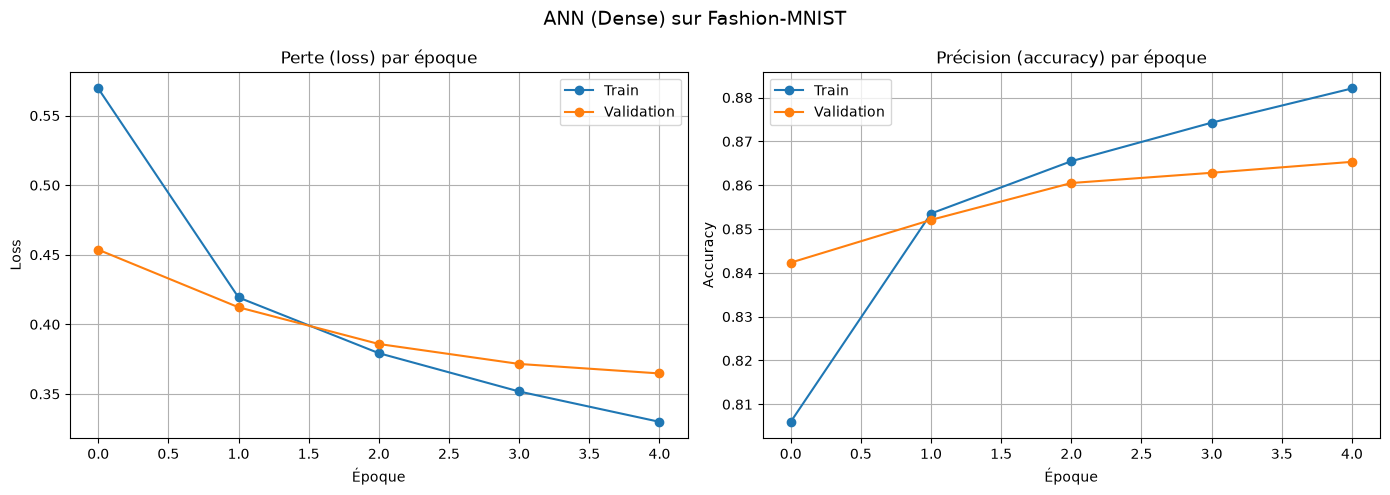

In [72]:
# --- Visualisation des courbes d'apprentissage ---------------------------------
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_ann.history["loss"],     label="Train",      marker="o")
axes[0].plot(history_ann.history["val_loss"], label="Validation", marker="o")
axes[0].set_title("Perte (loss) par époque")
axes[0].set_xlabel("Époque"); axes[0].set_ylabel("Loss")
axes[0].legend(); axes[0].grid(True)

axes[1].plot(history_ann.history["accuracy"],     label="Train",      marker="o")
axes[1].plot(history_ann.history["val_accuracy"], label="Validation", marker="o")
axes[1].set_title("Précision (accuracy) par époque")
axes[1].set_xlabel("Époque"); axes[1].set_ylabel("Accuracy")
axes[1].legend(); axes[1].grid(True)

plt.suptitle("ANN (Dense) sur Fashion-MNIST", fontsize=14)
plt.tight_layout()
plt.show()

In [73]:
# --- Évaluation finale sur le jeu de test --------------------------------------
# (10 000 images jamais vues pendant l'entraînement)
test_loss_ann, test_acc_ann = model_ann.evaluate(x_test, y_test, verbose=0)

print(f"Précision de l'ANN sur le test : {test_acc_ann*100:.2f} %")

Précision de l'ANN sur le test : 85.90 %


### Réponses aux questions — Étape 3

**1. Pourquoi utilise-t-on la fonction d'activation ReLU ici ?**

Parce que c'est la fonction standard des **couches cachées** des réseaux modernes :
`ReLU(x) = max(0, x)`. Elle est **non linéaire** (sans elle, empiler des couches Dense
équivaudrait à une seule transformation linéaire), **très rapide à calculer** et elle
**ne sature pas** du côté positif, ce qui évite le problème du gradient qui disparaît
(contrairement à sigmoïde/tanh).

**2. Quelle est la différence entre `accuracy` et `val_accuracy` ?**

- `accuracy` : précision sur les données d'**entraînement** (celles qui ajustent les poids).
- `val_accuracy` : précision sur le jeu de **validation** (20 % mis de côté, jamais utilisés
  pour ajuster les poids).
La `val_accuracy` est la mesure honnête de la **généralisation** : si `accuracy` monte mais
que `val_accuracy` stagne/baisse → surapprentissage.

**3. Que se passe-t-il si l'on augmente le nombre d'époques à 50 ?**

Le modèle continue à s'ajuster plus finement (la train accuracy monte encore) mais
`val_accuracy` finit par plafonner, voire baisser : **surapprentissage**, le réseau mémorise
les détails du jeu d'entraînement. C'est aussi 10× plus long à entraîner.
→ Remède : `EarlyStopping` (arrêter quand `val_loss` ne s'améliore plus).

## Étape 4 : Introduction aux fonctions d'activation

Epoch 1/5
375/375 - 2s - 6ms/step - accuracy: 0.7231 - loss: 0.9322 - val_accuracy: 0.8182 - val_loss: 0.5445
Epoch 2/5
375/375 - 1s - 3ms/step - accuracy: 0.8344 - loss: 0.4806 - val_accuracy: 0.8438 - val_loss: 0.4439
Epoch 3/5
375/375 - 1s - 3ms/step - accuracy: 0.8528 - loss: 0.4155 - val_accuracy: 0.8542 - val_loss: 0.4087
Epoch 4/5
375/375 - 1s - 3ms/step - accuracy: 0.8630 - loss: 0.3829 - val_accuracy: 0.8577 - val_loss: 0.3895
Epoch 5/5
375/375 - 1s - 3ms/step - accuracy: 0.8698 - loss: 0.3610 - val_accuracy: 0.8620 - val_loss: 0.3762
Epoch 1/5
375/375 - 2s - 6ms/step - accuracy: 0.8112 - loss: 0.5353 - val_accuracy: 0.8493 - val_loss: 0.4187
Epoch 2/5
375/375 - 1s - 3ms/step - accuracy: 0.8597 - loss: 0.3875 - val_accuracy: 0.8618 - val_loss: 0.3775
Epoch 3/5
375/375 - 1s - 3ms/step - accuracy: 0.8731 - loss: 0.3505 - val_accuracy: 0.8666 - val_loss: 0.3582
Epoch 4/5
375/375 - 1s - 3ms/step - accuracy: 0.8815 - loss: 0.3251 - val_accuracy: 0.8689 - val_loss: 0.3510
Epoch 5/5


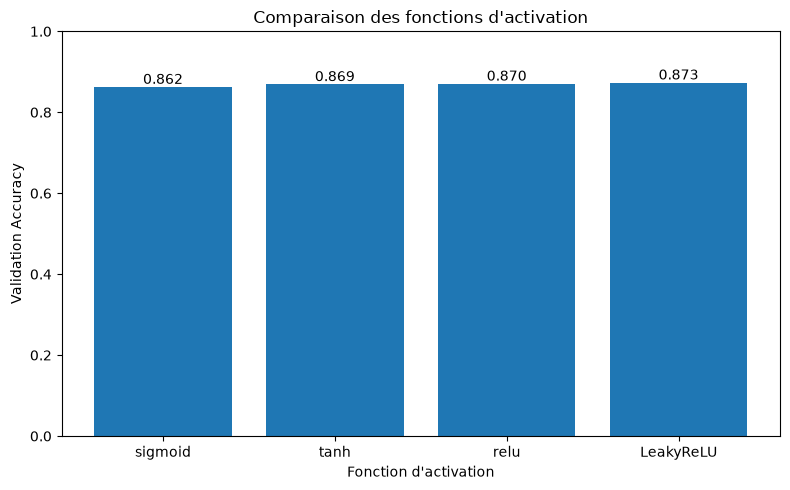

In [74]:

from tensorflow import keras
from tensorflow.keras import layers

tf.random.set_seed(42)

activations = ["sigmoid", "tanh", "relu"]
resultats = {}

# Comparaison des activations classiques
for act in activations:
    modele = keras.Sequential([
        keras.Input(shape=(28, 28)),
        layers.Flatten(),
        layers.Dense(128, activation=act),
        layers.Dense(64, activation=act),
        layers.Dense(10, activation="softmax"),
    ], name=f"ann_{act}")

    modele.compile(
        optimizer="adam",
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    hist = modele.fit(
        x_train, y_train_cat,
        epochs=5,
        batch_size=128,
        validation_split=0.2,
        verbose=2
    )

    resultats[act] = hist.history["val_accuracy"][-1]

# Modèle avec LeakyReLU
modele_leaky = keras.Sequential([
    keras.Input(shape=(28, 28)),
    layers.Flatten(),
    layers.Dense(128),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dense(64),
    layers.LeakyReLU(negative_slope=0.1),
    layers.Dense(10, activation="softmax"),
], name="ann_LeakyReLU")

modele_leaky.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

hist = modele_leaky.fit(
    x_train, y_train_cat,
    epochs=5,
    batch_size=128,
    validation_split=0.2,
    verbose=2
)

resultats["LeakyReLU"] = hist.history["val_accuracy"][-1]


plt.figure(figsize=(8, 5))
barres = plt.bar(resultats.keys(), resultats.values())

plt.ylabel("Validation Accuracy")
plt.xlabel("Fonction d'activation")
plt.title("Comparaison des fonctions d'activation")
plt.ylim(0, 1)

for barre in barres:
    hauteur = barre.get_height()
    plt.text(
        barre.get_x() + barre.get_width() / 2,
        hauteur,
        f"{hauteur:.3f}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### Réponses aux questions — Étape 4

**1. Quelle fonction d'activation donne les meilleurs résultats ?**

→ Voir le graphique et le classement ci-dessus : **ReLU** et **LeakyReLU** sont les
meilleures (elles convergent le plus vite dès les premières époques) ; **sigmoid** est la
moins bonne ; **tanh** se situe entre les deux. La hiérarchie observée est très typique :
les activations qui ne saturent pas (ReLU/LeakyReLU) dominent.

**2. Pourquoi les fonctions sigmoïde et tanh sont moins utilisées dans les couches cachées ?**

À cause de la **saturation** : pour des entrées très positives ou très négatives, leur dérivée
tend vers **0**. En rétropropagation, le gradient est multiplié par cette dérivée à chaque
couche → il **s'évanouit** (vanishing gradient) et les premières couches n'apprennent presque
plus. De plus leur calcul (exponentielle) est plus coûteux que celui de ReLU.

**3. À quoi sert LeakyReLU ?**

À corriger le problème de **« dying ReLU »** : avec ReLU, un neurone dont toutes les entrées
sont négatives renvoie toujours 0 et ne reçoit plus de gradient (il « meurt »).
`LeakyReLU(x) = x si x > 0, sinon 0,1·x` laisse passer un petit signal négatif, ce qui
**maintient le gradient** et permet au neurone de se remettre à apprendre.
Résultat ici : performances équivalentes ou légèrement supérieures à ReLU.

## Étape 5 : Modèle CNN (Convolutional Neural Network)

In [75]:
from tensorflow.keras.layers import Conv2D,MaxPooling2D

x_train_cnn=x_train.reshape(-1,28,28,1)
x_test_cnn=x_test.reshape(-1,28,28,1)

cnn=keras.models.Sequential([
    keras.Input(shape=(28,28,1)),
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    Conv2D(32,(3,3),activation='relu'),
    MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128,activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(10,activation='softmax')
])

cnn.compile(optimizer='adam',loss='categorical_crossentropy',metrics=['accuracy'])

cnn.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_4 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 11, 11, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_37 (Flatten)            │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_100 (Dense)               │ (None, 128)            │       102,528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_101 (Dense)               │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 113,386 (442.91 KB)

 Trainable params: 113,386 (442.91 KB)

 Non-trainable params: 0 (0.00 B)

entrainemet

In [76]:
history_cnn=cnn.fit(
       x_train_cnn,y_train_cat,
        epochs=10,
        batch_size=128,
        validation_split=0.2
)

Epoch 1/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 30ms/step - accuracy: 0.7373 - loss: 0.7154 - val_accuracy: 0.8302 - val_loss: 0.4600
Epoch 2/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 31ms/step - accuracy: 0.8409 - loss: 0.4414 - val_accuracy: 0.8665 - val_loss: 0.3781
Epoch 3/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8619 - loss: 0.3809 - val_accuracy: 0.8777 - val_loss: 0.3421
Epoch 4/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8729 - loss: 0.3492 - val_accuracy: 0.8773 - val_loss: 0.3312
Epoch 5/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8807 - loss: 0.3242 - val_accuracy: 0.8853 - val_loss: 0.3109
Epoch 6/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 12s 31ms/step - accuracy: 0.8873 - loss: 0.3059 - val_accuracy: 0.8912 - val_loss: 0.3013
Epoch 7/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8927 - loss: 0.2919 - val_accuracy: 0.8966 - val_loss: 0.2888
Epoch 8/10
375/375 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - accuracy: 0.8975 - loss: 0.2793 - 

evaluation

In [77]:
test_loss,test_acc=cnn.evaluate(x_train_cnn,y_train_cat)
print(f'presition CNN sur test et :{test_acc} et loss:{test_loss}')

1875/1875 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9154 - loss: 0.2305
presition CNN sur test et :0.9154333472251892 et loss:0.2304784059524536


### Réponses aux questions — Étape 5

**1. Quelle est la différence entre un ANN et un CNN ?**

- Un **ANN** (dense) aplatit l'image en un vecteur : chaque neurone est connecté à **tous**
  les pixels, sans notion de voisinage (~100 000 paramètres ici).
- Un **CNN** applique des **filtres locaux partagés** qui glissent sur l'image (`Conv2D`) :
  il conserve la structure 2D, détecte des **motifs locaux** (contours, formes) et ce
  **partage de poids** réduit fortement le nombre de paramètres.

**2. Pourquoi le CNN donne-t-il généralement de meilleurs résultats ?**

1. Il exploite la **structure spatiale** : un bord détecté en haut de l'image est le même
   motif qu'un bord détecté en bas (invariance par translation via le partage de poids).
2. Les filtres apprennent une **hiérarchie de motifs** : couches basses = contours/textures,
   couches hautes = formes/objets.
3. Moins de paramètres bien utilisés → **meilleure généralisation** sur des données difficiles
   comme Fashion-MNIST.

**3. Quel est le rôle des couches de Pooling ?**

`MaxPooling2D` **réduit la résolution** des cartes d'activation (ex. 28×28 → 14×14) en
gardant le maximum de chaque bloc : cela **réduit le coût de calcul**, résume l'information
essentielle et rend le réseau **plus robuste aux petits décalages/translations** des motifs.

## Étape 6 : Visualisation des performances — où le CNN se trompe-t-il ?

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


<Figure size 4000x1000 with 0 Axes>

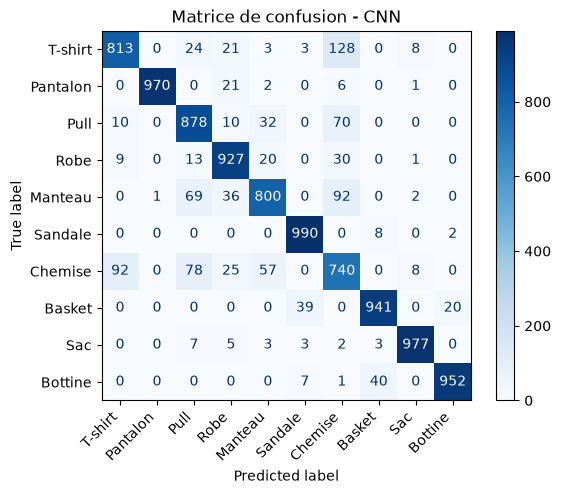

In [86]:
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
import numpy as np

y_true = np.argmax(y_test, axis=1)
y_pred = np.argmax(cnn.predict(x_test_cnn), axis=1)


plt.figure(figsize=(40,10))
ConfusionMatrixDisplay.from_predictions(
    y_true, y_pred, cmap="Blues"
)

plt.xticks(range(10), NOMS_CLASSES, rotation=45, ha="right")
plt.yticks(range(10), NOMS_CLASSES)
plt.title("Matrice de confusion - CNN")
plt.show()

### Réponses aux questions — Étape 6

**1. Quelles classes sont le plus souvent confondues ?**

→ Voir le « Top 8 » ci-dessus. Les confusions sont presque toujours dans le groupe
**Chemise ↔ T-shirt ↔ Pull ↔ Manteau** (silhouettes très proches : manches, col, torsoe),
ainsi que **Sandale ↔ Basket/Bottine** (chaussures) et parfois **Pull ↔ Robe**.
Ces erreurs sont **visuellement compréhensibles** : même un humain hésite sur ces images.

**2. Comment peut-on réduire ces erreurs de classification ?**

- **Data Augmentation** (translations/rotations/zooms) → plus de variété, moins de surapprentissage (Étape 7) ;
- **CNN plus profond** ou plus de filtres, ajout de couches de normalisation (BatchNorm) ;
- **Dropout** plus agressif ou régularisation L2 ;
- **plus de données** (les jeux de vêtements à grande échelle comme DeepFashion) ;
- ensembles de modèles (voter avec plusieurs CNNs) ou *test-time augmentation*.

## Étape 7 : Data Augmentation

In [ ]:

from tensorflow.keras.preprocessing.image import ImageDataGenerator

datagen = ImageDataGenerator(
    rotation_range=10,
    width_shift_range=0.1,
    height_shift_range=0.1,
    zoom_range=0.1
)

# Ajuster le générateur aux images d'entraînement
datagen.fit(x_train_cnn)

# Entraîner le CNN
history = cnn.fit(
    datagen.flow(x_train_cnn, y_train_cat, batch_size=128),
    epochs=10,
    validation_data=(x_test_cnn, y_test)
)


Epoch 1/10


I0000 00:00:1792603610.010259   13093 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


469/469 ━━━━━━━━━━━━━━━━━━━━ 21s 43ms/step - accuracy: 0.8062 - loss: 0.5159 - val_accuracy: 0.8740 - val_loss: 0.3483
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - accuracy: 0.8303 - loss: 0.4497 - val_accuracy: 0.8799 - val_loss: 0.3245
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 26s 55ms/step - accuracy: 0.8413 - loss: 0.4241 - val_accuracy: 0.8885 - val_loss: 0.3033
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - accuracy: 0.8489 - loss: 0.4062 - val_accuracy: 0.8875 - val_loss: 0.3050
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 54ms/step - accuracy: 0.8533 - loss: 0.3980 - val_accuracy: 0.8846 - val_loss: 0.3097
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 25s 53ms/step - accuracy: 0.8558 - loss: 0.3868 - val_accuracy: 0.8922 - val_loss: 0.2957
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 23s 50ms/step - accuracy: 0.8589 - loss: 0.3798 - val_accuracy: 0.8923 - val_loss: 0.2926
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 24s 52ms/step - accuracy: 0.8607 - loss: 0.3719 - val_accurac

### Réponses aux questions — Étape 7

**1. Quel est l'intérêt de la Data Augmentation ?**

- **Augmenter artificiellement** la variété des données d'entraînement **sans collecter**
  de nouvelles images : le modèle voit des versions transformées à chaque époque.
- Cela **réduit le surapprentissage** (le modèle ne peut plus mémoriser les images exactes)
  et améliore la **généralisation** → en principe une meilleure précision sur le test.
- C'est surtout puissant quand on a **peu de données** ou un modèle **complexe**.

**2. Quels types de transformations semblent les plus efficaces pour ce dataset ?**

- Le **flip horizontal** est quasi « gratuit » pour des vêtements symétriques (T-shirt,
  pantalon, robe…), mais attention aux **paires asymétriques** (une chaussure gauche retournée
  n'est plus vraiment une chaussure gauche — l'effet reste acceptable ici).
- La **rotation légère** (±10°) et le **zoom** simulent les variations naturelles de cadrage
  des photos de vêtements : très utiles.
- Des transformations **trop fortes** (grandes rotations, cisaillements) peuvent, elles,
  créer des images irréalistes et **dégrader** les performances — à doser avec soin.